# RQ1 property freshness and session recovery evaluation

## Evaluation purpose

RQ1 asks how the edge-IoT monitoring framework can be extended and formalised as a low-cost digital-twin architecture that continuously synchronises a physical indoor testbed with its 2D room-state representation. This notebook evaluates three observable mechanisms that support that synchronisation:

1. **Property-freshness conformance:** telemetry that stops updating is declared `STALE` according to the configured property limit.
2. **Fault isolation:** interrupting one node does not make properties from unaffected nodes stale.
3. **Session-aware restoration:** after release, the interrupted node establishes a new `session_id` and its properties return to `FRESH`.

## Evidence boundary

The pinned campaign is a **pilot bootloader-hold evaluation**. Holding a microcontroller in its ROM bootloader suspends application-level telemetry and produces a new device session after release. It is not a physical power cut, a broker outage, or a controlled packet-loss experiment. Reported times are **host-observed freshness intervals**; they include device restart, publication scheduling, transport, backend processing, and observation cadence. They must not be described as isolated network latency. The dataset records backend state transitions but does not timestamp rendering in the 2D dashboard.


Saved results and plots are included below; no rerun is needed to inspect them. Regeneration is optional.

Scope: eighteen interruption-and-restoration cycles using bootloader hold. The intervention suspends application telemetry; it is not a physical power interruption.

## 1. Pinned evidence and reproducibility

The analysis is pinned to `EXP_RQ1_BOOTLOADER_HOLD_20261016_224955`. It does not select the newest matching directory. This prevents a later experiment from silently changing the reported results. Source metadata and file hashes are exported with the analysis outputs.


In [1]:
from pathlib import Path
import hashlib
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from IPython.display import display, Markdown

try:
    plt.style.use("seaborn-v0_8-whitegrid")
except OSError:
    plt.style.use("ggplot")

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", 180)
plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "font.size": 9.5,
    "axes.titlesize": 10.5,
    "axes.labelsize": 9.5,
    "legend.fontsize": 8,
})

from pathlib import Path
import sys

REPO_ROOT = next((p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
                  if (p / "notebooks").is_dir() and (p / "src" / "indoortwin" / "paths.py").is_file()), None)
if REPO_ROOT is None:
    raise FileNotFoundError("Open this notebook from inside the repository.")
sys.path.insert(0, str(REPO_ROOT / "src"))
NOTEBOOK_DIR = REPO_ROOT / "data/rq1_repeated"
EXPERIMENT_ID = "EXP_RQ1_BOOTLOADER_HOLD_20261016_224955"
SOURCE = NOTEBOOK_DIR / EXPERIMENT_ID
if not SOURCE.exists():
    raise FileNotFoundError(
        f"Expected {EXPERIMENT_ID} beside the notebook. Run the notebook with working directory {NOTEBOOK_DIR}."
    )

OUTPUT_ROOT = REPO_ROOT / "results/rq1_repeated"
FIGURE_DIR = OUTPUT_ROOT / "figures"
TABLE_DIR = OUTPUT_ROOT / "tables"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

NODE_ORDER = ["ENV-IN-01", "ENV-OUT-01", "OCC-IN-01", "HEAT-MON-01", "VIB-FAN-01", "VENT-CTRL-01"]
REPETITION_COLORS = {1: "#214761", 2: "#3d7ea6", 3: "#79add2"}
NODE_COLORS = {
    "ENV-IN-01": "#1f4e79",
    "ENV-OUT-01": "#4c78a8",
    "OCC-IN-01": "#b85c38",
    "HEAT-MON-01": "#7a5195",
    "VIB-FAN-01": "#2f6f4e",
    "VENT-CTRL-01": "#d97706",
}
FLAG_COLUMNS = [
    "healthy_window_pass", "session_changed_after_reboot", "target_stale",
    "other_nodes_fresh", "recovered", "occupancy_unchanged", "cycle_pass",
    "online_initial", "telemetry_present", "stable_session", "session_recovery_new_id",
    "sequence_ok", "properties_became_stale", "recovery_to_fresh", "overall_pass",
    "all_properties_fresh", "session_constant", "sequence_non_decreasing", "pass", "unchanged",
]

def apply_flags(frame):
    frame = frame.copy()
    for column in FLAG_COLUMNS:
        if column in frame.columns and frame[column].dtype != bool:
            frame[column] = frame[column].astype(str).str.strip().str.lower().isin(["true", "1"])
    return frame

def sha256(path):
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        for block in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

manifest = json.loads((SOURCE / "experiment_manifest.json").read_text(encoding="utf-8"))
scope = json.loads((SOURCE / "bootloader_hold_scope.json").read_text(encoding="utf-8"))
integrity_record = json.loads((SOURCE / "rq1_integrity_completeness.json").read_text(encoding="utf-8"))

cycles = apply_flags(pd.read_csv(SOURCE / "rq1_repeated_validation_summary.csv"))
nodes = apply_flags(pd.read_csv(SOURCE / "rq1_node_summary.csv"))
healthy = apply_flags(pd.read_csv(SOURCE / "rq1_healthy_window_summary.csv"))
occupancy = apply_flags(pd.read_csv(SOURCE / "rq1_occupancy_retention.csv"))
properties = pd.read_csv(SOURCE / "rq1_property_summary.csv")
transitions = pd.read_csv(SOURCE / "state_transitions.csv")
sessions = pd.DataFrame(integrity_record["sessions"])

for column in ["disconnect_confirmed_time", "stale_detected_time", "reconnect_confirmed_time", "node_properties_fresh_time"]:
    cycles[column] = pd.to_datetime(cycles[column], utc=True)
transitions["transition_time"] = pd.to_datetime(transitions["transition_time"], utc=True)
transitions["node_id"] = transitions["source_message_id"].astype(str).str.split("/").str[0]

display(pd.DataFrame([
    {"field": "Experiment", "value": manifest["experiment_id"]},
    {"field": "Phase", "value": manifest["phase"]},
    {"field": "Intervention", "value": scope["dropout_mode"]},
    {"field": "Physical power cut used", "value": scope["physical_power_cut_used"]},
    {"field": "Registry", "value": manifest["registry_version"]},
    {"field": "Backend", "value": manifest["backend"]},
    {"field": "Recorded cycles", "value": len(cycles)},
]))

,field,value
0,Experiment,EXP_RQ1_BOOTLOADER_HOLD_20261016_224955
1,Phase,PILOT
2,Intervention,BOOTLOADER_HOLD
3,Physical power cut used,False
4,Registry,room01-entity-registry-v1.3
5,Backend,IndoorTwin RQ1 Backend v1.2
6,Recorded cycles,18


## 2. Evidence-integrity checks

These checks establish that the pinned package is internally complete before computing evaluation results. They verify the intervention metadata, expected cycle structure, node coverage, transition counts and session-integrity record. A failed assertion stops the notebook rather than producing partially valid figures.


In [2]:
stale = transitions.loc[
    transitions["old_quality"].eq("FRESH") & transitions["new_quality"].eq("STALE")
].copy()
fresh = transitions.loc[
    transitions["old_quality"].eq("STALE") & transitions["new_quality"].eq("FRESH")
].copy()

integrity_checks = pd.DataFrame([
    {"check": "Pinned experiment identifier", "met": manifest["experiment_id"] == EXPERIMENT_ID, "observed": manifest["experiment_id"]},
    {"check": "Pilot phase retained", "met": manifest["phase"] == "PILOT", "observed": manifest["phase"]},
    {"check": "Bootloader-hold intervention", "met": scope["dropout_mode"] == "BOOTLOADER_HOLD", "observed": scope["dropout_mode"]},
    {"check": "No physical power-cut claim", "met": scope["physical_power_cut_used"] is False, "observed": scope["physical_power_cut_used"]},
    {"check": "Three repetitions", "met": cycles["repetition"].nunique() == 3, "observed": cycles["repetition"].nunique()},
    {"check": "Eighteen cycles", "met": len(cycles) == 18, "observed": len(cycles)},
    {"check": "Six expected nodes", "met": set(cycles["node_id"]) == set(NODE_ORDER), "observed": cycles["node_id"].nunique()},
    {"check": "Three cycles per node", "met": cycles.groupby("node_id").size().eq(3).all(), "observed": cycles.groupby("node_id").size().to_dict()},
    {"check": "Eighty-one FRESH-to-STALE transitions", "met": len(stale) == 81, "observed": len(stale)},
    {"check": "Eighty-one STALE-to-FRESH transitions", "met": len(fresh) == 81, "observed": len(fresh)},
    {"check": "All recorded sessions passed integrity checks", "met": bool(sessions["pass"].all()), "observed": f"{int(sessions['pass'].sum())}/{len(sessions)}"},
])
display(integrity_checks)
if not bool(integrity_checks["met"].all()):
    raise AssertionError("One or more evidence-integrity checks failed.")

,check,met,observed
0,Pinned experiment identifier,True,EXP_RQ1_BOOTLOADER_HOLD_20261016_224955
1,Pilot phase retained,True,PILOT
2,Bootloader-hold intervention,True,BOOTLOADER_HOLD
3,No physical power-cut claim,True,False
4,Three repetitions,True,3
5,Eighteen cycles,True,18
6,Six expected nodes,True,6
7,Three cycles per node,True,"{'ENV-IN-01': 3, 'ENV-OUT-01': 3, 'HEAT-MON-01': 3, 'OCC-IN-01': 3, 'VENT-CTRL-01': 3, 'VIB-FAN-01': 3}"
8,Eighty-one FRESH-to-STALE transitions,True,81
9,Eighty-one STALE-to-FRESH transitions,True,81


## 3. Operational measures and conformance criteria

- **Host-observed time to all properties stale:** interruption confirmation to the observation that every target property is `STALE`. This depends on the age of the last accepted reading when the intervention begins.
- **Property threshold-crossing overshoot:** freshness age at the `FRESH → STALE` transition minus that property's configured freshness limit. This is the appropriate measure of freshness-rule timing conformance.
- **Host-observed time to all properties fresh:** intervention release to the observation that every target property has returned to `FRESH` under the recovery session.
- **Observation deadline:** the longest property freshness limit on the node plus the protocol's five-second observation margin. It is an experimental conformance deadline, not a network-latency requirement.


In [3]:
cycles["host_observed_to_all_stale_s"] = (
    cycles["stale_detected_time"] - cycles["disconnect_confirmed_time"]
).dt.total_seconds()
cycles["host_observed_to_all_fresh_s"] = (
    cycles["node_properties_fresh_time"] - cycles["reconnect_confirmed_time"]
).dt.total_seconds()
cycles["within_observation_deadline"] = (
    cycles["host_observed_to_all_stale_s"] <= cycles["required_stale_wait_seconds"]
)
cycles["occupancy_retention_if_applicable"] = (
    cycles["node_id"].ne("OCC-IN-01") | cycles["occupancy_unchanged"]
)
cycles["criterion_met_recomputed"] = (
    cycles["healthy_window_pass"]
    & cycles["target_stale"]
    & cycles["other_nodes_fresh"]
    & cycles["recovered"]
    & cycles["session_changed_after_reboot"]
    & cycles["occupancy_retention_if_applicable"]
    & cycles["within_observation_deadline"]
)
cycles["recorded_agrees"] = cycles["criterion_met_recomputed"] == cycles["cycle_pass"]

class_lookup = (
    properties[["node_id", "entity_id", "property", "freshness_class"]]
    .drop_duplicates()
    .rename(columns={"property": "property_name"})
)
stale["threshold_crossing_overshoot_s"] = stale["freshness_age_s"] - stale["threshold_s"]
stale = stale.merge(
    class_lookup,
    left_on=["node_id", "entity_id", "property"],
    right_on=["node_id", "entity_id", "property_name"],
    how="left",
)

node_sequence_ok = nodes.set_index("node_id")["sequence_ok"].to_dict()
cycles["sequence_integrity"] = cycles["node_id"].map(node_sequence_ok).fillna(False)
cycles["node_order"] = cycles["node_id"].map({node: index for index, node in enumerate(NODE_ORDER)})

cycle_metrics = cycles[[
    "repetition", "node_id", "dropout_mode", "disconnect_confirmed_time", "stale_detected_time",
    "reconnect_confirmed_time", "node_properties_fresh_time", "required_stale_wait_seconds",
    "host_observed_to_all_stale_s", "host_observed_to_all_fresh_s",
    "healthy_window_pass", "target_stale", "other_nodes_fresh", "recovered",
    "session_changed_after_reboot", "occupancy_unchanged", "occupancy_retention_if_applicable", "sequence_integrity",
    "within_observation_deadline", "criterion_met_recomputed", "cycle_pass", "recorded_agrees",
]].assign(
    _node_order=lambda frame: frame["node_id"].map({node: index for index, node in enumerate(NODE_ORDER)})
).sort_values(["repetition", "_node_order"]).drop(columns="_node_order")

display(cycle_metrics.round(3))
cycle_metrics.to_csv(TABLE_DIR / "rq1_cycle_metrics.csv", index=False)
stale.to_csv(TABLE_DIR / "rq1_property_transition_metrics.csv", index=False)
sessions.to_csv(TABLE_DIR / "rq1_session_integrity_metrics.csv", index=False)

C:\Users\AMN\AppData\Local\Temp\ipykernel_38792\3159712837.py:52: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(cycle_metrics.round(3))


,repetition,node_id,dropout_mode,disconnect_confirmed_time,stale_detected_time,reconnect_confirmed_time,node_properties_fresh_time,required_stale_wait_seconds,host_observed_to_all_stale_s,host_observed_to_all_fresh_s,healthy_window_pass,target_stale,other_nodes_fresh,recovered,session_changed_after_reboot,occupancy_unchanged,occupancy_retention_if_applicable,sequence_integrity,within_observation_deadline,criterion_met_recomputed,cycle_pass,recorded_agrees
0,1,ENV-IN-01,BOOTLOADER_HOLD,2026-10-16 09:50:28.129850+00:00,2026-10-16 09:50:57.148207+00:00,2026-10-16 09:50:58.590763+00:00,2026-10-16 09:51:07.597610+00:00,35,29.018,9.007,True,True,True,True,True,True,True,True,True,True,True,True
1,1,ENV-OUT-01,BOOTLOADER_HOLD,2026-10-16 09:51:08.931891+00:00,2026-10-16 09:51:36.980733+00:00,2026-10-16 09:51:38.405783+00:00,2026-10-16 09:51:47.425484+00:00,35,28.049,9.020,True,True,True,True,True,True,True,True,True,True,True,True
2,1,OCC-IN-01,BOOTLOADER_HOLD,2026-10-16 09:51:48.762508+00:00,2026-10-16 09:52:18.779239+00:00,2026-10-16 09:52:20.230836+00:00,2026-10-16 09:52:26.234254+00:00,35,30.017,6.003,True,True,True,True,True,True,True,True,True,True,True,True
3,1,HEAT-MON-01,BOOTLOADER_HOLD,2026-10-16 09:52:26.905249+00:00,2026-10-16 09:52:56.923618+00:00,2026-10-16 09:52:57.679871+00:00,2026-10-16 09:53:02.683583+00:00,35,30.018,5.004,True,True,True,True,True,True,True,True,True,True,True,True
4,1,VIB-FAN-01,BOOTLOADER_HOLD,2026-10-16 09:53:04.030254+00:00,2026-10-16 09:53:13.035394+00:00,2026-10-16 09:53:14.489672+00:00,2026-10-16 09:53:20.493189+00:00,15,9.005,6.004,True,True,True,True,True,True,True,True,True,True,True,True
5,1,VENT-CTRL-01,BOOTLOADER_HOLD,2026-10-16 09:53:21.845872+00:00,2026-10-16 09:53:31.853328+00:00,2026-10-16 09:53:33.324312+00:00,2026-10-16 09:53:36.327374+00:00,15,10.007,3.003,True,True,True,True,True,True,True,True,True,True,True,True
6,2,ENV-IN-01,BOOTLOADER_HOLD,2026-10-16 09:54:07.703120+00:00,2026-10-16 09:54:36.735328+00:00,2026-10-16 09:54:38.192854+00:00,2026-10-16 09:54:47.208096+00:00,35,29.032,9.015,True,True,True,True,True,True,True,True,True,True,True,True
7,2,ENV-OUT-01,BOOTLOADER_HOLD,2026-10-16 09:54:48.571494+00:00,2026-10-16 09:55:16.586603+00:00,2026-10-16 09:55:18.041265+00:00,2026-10-16 09:55:27.048948+00:00,35,28.015,9.008,True,True,True,True,True,True,True,True,True,True,True,True
8,2,OCC-IN-01,BOOTLOADER_HOLD,2026-10-16 09:55:28.423796+00:00,2026-10-16 09:55:58.439103+00:00,2026-10-16 09:55:59.871678+00:00,2026-10-16 09:56:05.881732+00:00,35,30.015,6.010,True,True,True,True,True,True,True,True,True,True,True,True
9,2,HEAT-MON-01,BOOTLOADER_HOLD,2026-10-16 09:56:06.552515+00:00,2026-10-16 09:56:36.572700+00:00,2026-10-16 09:56:37.317852+00:00,2026-10-16 09:56:42.331474+00:00,35,30.020,5.014,True,True,True,True,True,True,True,True,True,True,True,True


## 4. Representative freshness-loss and restoration trajectories

This main-text figure separates freshness loss from restoration for one node in each configured freshness class. `VENT-CTRL-01` represents the 10 s FAST class and `ENV-IN-01` represents the 30 s MEDIUM class. In the left column, time is property freshness age, so the configured limit can be interpreted directly. In the right column, time is reset to zero when the intervention is released. All three technical repetitions are shown individually. The restoration step curves use backend transition timestamps; open triangles mark the subsequent host observation confirming that all target properties were `FRESH`.

The figure is designed to complement, rather than repeat, the exact node-level values reported in the summary table. It shows the progression of property-state changes that a table cannot show.


In [4]:
REPRESENTATIVE_NODES = [
    ("VENT-CTRL-01", "FAST", 10.0),
    ("ENV-IN-01", "MEDIUM", 30.0),
]

representative_rows = []
figure, axes = plt.subplots(2, 2, figsize=(12.4, 7.8), sharey=True)

for row_index, (node, freshness_class, configured_limit_s) in enumerate(REPRESENTATIVE_NODES):
    stale_axis = axes[row_index, 0]
    recovery_axis = axes[row_index, 1]
    node_cycles = cycles.loc[cycles["node_id"].eq(node)].sort_values("repetition")

    for cycle in node_cycles.itertuples(index=False):
        color = REPETITION_COLORS[int(cycle.repetition)]
        window = transitions.loc[
            transitions["node_id"].eq(node)
            & transitions["transition_time"].between(
                cycle.disconnect_confirmed_time - pd.Timedelta(milliseconds=500),
                cycle.node_properties_fresh_time + pd.Timedelta(seconds=1),
            )
        ].copy()
        stale_rows = window.loc[
            window["old_quality"].eq("FRESH") & window["new_quality"].eq("STALE")
        ].sort_values("freshness_age_s")
        fresh_rows = window.loc[
            window["old_quality"].eq("STALE") & window["new_quality"].eq("FRESH")
        ].sort_values("transition_time")
        property_count = int(stale_rows.groupby(["entity_id", "property"]).ngroups)

        # Stale-declaration phase: percentage remaining FRESH against property age.
        stale_grouped = (
            stale_rows.groupby("freshness_age_s", as_index=False)
            .size()
            .sort_values("freshness_age_s")
        )
        stale_times = [max(0.0, configured_limit_s - 1.0)]
        stale_percent = [100.0]
        remaining = property_count
        for event in stale_grouped.itertuples(index=False):
            remaining -= int(event.size)
            percent = 100.0 * remaining / property_count
            stale_times.append(float(event.freshness_age_s))
            stale_percent.append(percent)
            representative_rows.append({
                "node_id": node,
                "freshness_class": freshness_class,
                "repetition": int(cycle.repetition),
                "phase": "stale_declaration",
                "time_basis": "property_freshness_age_s",
                "time_s": float(event.freshness_age_s),
                "percent_properties_in_target_state": percent,
            })
        stale_times.append(max(stale_times[-1] + 0.25, configured_limit_s + 1.1))
        stale_percent.append(stale_percent[-1])
        stale_axis.step(
            stale_times, stale_percent, where="post", color=color, linewidth=2.0,
            label=f"Repetition {int(cycle.repetition)}"
        )

        # Restoration phase: percentage restored after intervention release.
        recovery_events = pd.DataFrame({
            "elapsed_s": (
                fresh_rows["transition_time"] - cycle.reconnect_confirmed_time
            ).dt.total_seconds()
        })
        recovery_grouped = (
            recovery_events.loc[recovery_events["elapsed_s"].ge(0)]
            .groupby("elapsed_s", as_index=False)
            .size()
            .sort_values("elapsed_s")
        )
        recovery_times = [0.0]
        restored_percent = [0.0]
        restored = 0
        for event in recovery_grouped.itertuples(index=False):
            restored += int(event.size)
            percent = 100.0 * restored / property_count
            recovery_times.append(float(event.elapsed_s))
            restored_percent.append(percent)
            representative_rows.append({
                "node_id": node,
                "freshness_class": freshness_class,
                "repetition": int(cycle.repetition),
                "phase": "freshness_restoration",
                "time_basis": "seconds_after_intervention_release",
                "time_s": float(event.elapsed_s),
                "percent_properties_in_target_state": percent,
            })
        recovery_times.append(recovery_times[-1] + 0.5)
        restored_percent.append(restored_percent[-1])
        recovery_axis.step(
            recovery_times, restored_percent, where="post", color=color, linewidth=2.0,
            label=f"Repetition {int(cycle.repetition)}"
        )
        host_confirmed_s = (
            cycle.node_properties_fresh_time - cycle.reconnect_confirmed_time
        ).total_seconds()
        recovery_axis.scatter(
            [host_confirmed_s], [100.0], marker="v", s=48,
            facecolor="white", edgecolor=color, linewidth=1.3, zorder=6
        )
        representative_rows.append({
            "node_id": node,
            "freshness_class": freshness_class,
            "repetition": int(cycle.repetition),
            "phase": "host_all_fresh_confirmation",
            "time_basis": "seconds_after_intervention_release",
            "time_s": float(host_confirmed_s),
            "percent_properties_in_target_state": 100.0,
        })

    stale_axis.axvline(
        configured_limit_s, color="#c45911", linestyle="--", linewidth=1.4,
        label=f"Configured limit ({configured_limit_s:.0f} s)"
    )
    stale_axis.set_xlim(configured_limit_s - 1.0, configured_limit_s + 1.1)
    stale_axis.set_title(f"{node}, {configured_limit_s:.0f} s freshness limit: stale declaration")
    stale_axis.set_xlabel("Property freshness age (seconds)")
    stale_axis.set_ylabel("Target properties remaining FRESH (%)")

    recovery_axis.set_xlim(left=0)
    recovery_axis.set_title(f"{node}, {configured_limit_s:.0f} s freshness limit: restoration")
    recovery_axis.set_xlabel("Seconds after intervention release")
    recovery_axis.set_ylabel("Target properties restored to FRESH (%)")

    for axis in (stale_axis, recovery_axis):
        axis.set_ylim(-3, 103)
        axis.set_yticks([0, 25, 50, 75, 100])

figure.legend(
    handles=[
        plt.Line2D([0], [0], color=REPETITION_COLORS[rep], linewidth=2.0, label=f"Repetition {rep}")
        for rep in (1, 2, 3)
    ] + [
        plt.Line2D([0], [0], color="#c45911", linestyle="--", linewidth=1.4, label="Configured freshness limit"),
        plt.Line2D([0], [0], marker="v", markerfacecolor="white", markeredgecolor="#555555", linestyle="None", label="Host confirmed all FRESH")
    ],
    frameon=False, loc="upper center", ncol=5, bbox_to_anchor=(0.5, 1.02)
)
figure.suptitle("Property-freshness loss and restoration under 10 s and 30 s limits", y=1.08, fontsize=13)
figure.tight_layout()
for suffix in ("png", "pdf"):
    figure.savefig(FIGURE_DIR / f"figure_rq1_representative_phase_response.{suffix}", bbox_inches="tight")
plt.close("all")

pd.DataFrame(representative_rows).to_csv(
    TABLE_DIR / "rq1_representative_phase_response.csv", index=False
)

## 5. Supplementary all-node cycle-aligned freshness response

For completeness, each panel shows the number of target-node properties still classified `FRESH` after the bootloader hold was confirmed. The three lines are technical repetitions on the same apparatus. Triangles mark release of the intervention for each repetition; the dotted vertical line is the protocol's observation deadline. This figure demonstrates transition completeness and repeatability without implying that the repetitions are independent deployments.


In [5]:
count_rows = []
figure, axes = plt.subplots(2, 3, figsize=(13.2, 7.3))

for axis, node in zip(axes.ravel(), NODE_ORDER):
    node_cycles = cycles.loc[cycles["node_id"].eq(node)].sort_values("repetition")
    node_property_count = 0
    panel_end = 0.0
    for cycle in node_cycles.itertuples(index=False):
        window = transitions.loc[
            transitions["node_id"].eq(node)
            & transitions["transition_time"].between(
                cycle.disconnect_confirmed_time - pd.Timedelta(milliseconds=500),
                cycle.node_properties_fresh_time + pd.Timedelta(seconds=1),
            )
        ]
        stale_rows = window.loc[
            window["old_quality"].eq("FRESH") & window["new_quality"].eq("STALE")
        ]
        fresh_rows = window.loc[
            window["old_quality"].eq("STALE") & window["new_quality"].eq("FRESH")
        ]
        node_property_count = int(stale_rows.groupby(["entity_id", "property"]).ngroups)

        events = []
        for row in stale_rows.itertuples(index=False):
            events.append(((row.transition_time - cycle.disconnect_confirmed_time).total_seconds(), -1))
        for row in fresh_rows.itertuples(index=False):
            events.append(((row.transition_time - cycle.disconnect_confirmed_time).total_seconds(), 1))
        event_frame = pd.DataFrame(events, columns=["elapsed_s", "delta"])
        event_frame = event_frame.loc[event_frame["elapsed_s"].ge(0)]
        grouped = event_frame.groupby("elapsed_s", as_index=False)["delta"].sum().sort_values("elapsed_s")

        times = [0.0]
        counts = [node_property_count]
        current = node_property_count
        for event in grouped.itertuples(index=False):
            current += int(event.delta)
            times.append(float(event.elapsed_s))
            counts.append(current)
            count_rows.append({
                "repetition": int(cycle.repetition),
                "node_id": node,
                "seconds_after_interruption": float(event.elapsed_s),
                "properties_remaining_fresh": current,
                "target_property_count": node_property_count,
            })

        release_s = (cycle.reconnect_confirmed_time - cycle.disconnect_confirmed_time).total_seconds()
        end_s = max(times[-1], release_s) + 1.5
        panel_end = max(panel_end, end_s)
        times.append(end_s)
        counts.append(current)
        color = REPETITION_COLORS[int(cycle.repetition)]
        axis.step(
            times, counts, where="post", color=color, linewidth=1.8,
            label=f"Repetition {int(cycle.repetition)}"
        )
        axis.scatter(
            [release_s], [-0.08], marker="v", s=34, color=color,
            clip_on=False, zorder=5
        )

    deadline_s = float(node_cycles["required_stale_wait_seconds"].iloc[0])
    axis.axvline(0, color="#555555", linewidth=0.9)
    axis.axvline(deadline_s, color="#c45911", linestyle=":", linewidth=1.4)
    axis.set_xlim(-1, panel_end + 1)
    axis.set_ylim(-0.25, node_property_count + 0.65)
    axis.set_yticks(range(node_property_count + 1))
    property_label = "property" if node_property_count == 1 else "properties"
    axis.set_title(f"{node} · {node_property_count} {property_label}")
    axis.set_xlabel("Seconds after intervention confirmation")

axes[0, 0].set_ylabel("Target properties remaining FRESH")
axes[1, 0].set_ylabel("Target properties remaining FRESH")
figure.legend(
    handles=[
        plt.Line2D([0], [0], color=REPETITION_COLORS[rep], linewidth=1.8, label=f"Repetition {rep}")
        for rep in (1, 2, 3)
    ] + [
        plt.Line2D([0], [0], color="#555555", linewidth=0.9, label="Intervention confirmed"),
        plt.Line2D([0], [0], marker="v", color="#555555", linestyle="None", label="Intervention released"),
        plt.Line2D([0], [0], color="#c45911", linestyle=":", linewidth=1.4, label="Observation deadline"),
    ],
    frameon=False, loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.03)
)
figure.suptitle("Cycle-aligned target-property freshness response", y=1.09, fontsize=13)
figure.tight_layout()
for suffix in ("png", "pdf"):
    figure.savefig(FIGURE_DIR / f"figure_rq1_cycle_aligned_freshness.{suffix}", bbox_inches="tight")
plt.close("all")

pd.DataFrame(count_rows).to_csv(TABLE_DIR / "rq1_cycle_aligned_freshness.csv", index=False)

## 6. Freshness-rule conformance and restoration interval

The left panel reports the delay between each configured freshness limit and its observed `FRESH → STALE` transition. The shaded band represents one nominal freshness-evaluation cycle (1.0 s), matching the implementation cadence. For this pilot dataset it is an implementation-aligned reference, not a retrospectively claimed pre-specified acceptance criterion. It should be stated in the methodology before a final evaluation is run.

The right panel reports release-to-restoration time for every cycle. Individual observations are retained because there are only three recovery repetitions per node. The diamond is the median and the line is the observed min–max range; no population-level confidence interval is inferred from these technical repetitions.


In [6]:
class_order = [name for name in ["FAST", "MEDIUM", "EVENT"] if name in set(stale["freshness_class"].dropna())]
class_labels = {"FAST": "10 s limit", "MEDIUM": "30 s limit", "EVENT": "Event-driven"}
NOMINAL_FRESHNESS_EVALUATION_CYCLE_S = 1.0
figure, axes = plt.subplots(1, 2, figsize=(12.2, 5.6))
axes[0].axhspan(0, NOMINAL_FRESHNESS_EVALUATION_CYCLE_S, color="#d9ead3", alpha=0.55, zorder=0)

for x, freshness_class in enumerate(class_order):
    values = stale.loc[
        stale["freshness_class"].eq(freshness_class), "threshold_crossing_overshoot_s"
    ].sort_values().to_numpy()
    offsets = np.linspace(-0.22, 0.22, len(values)) if len(values) > 1 else np.array([0.0])
    axes[0].scatter(
        x + offsets, values, s=25, color="#3d7ea6", alpha=0.62,
        edgecolor="white", linewidth=0.35
    )
    axes[0].vlines(x, values.min(), values.max(), color="#263238", linewidth=1.1)
    axes[0].scatter(x, np.median(values), marker="D", s=48, color="#c45911", zorder=5)

axes[0].axhline(0, color="#555555", linestyle="--", linewidth=0.9)
axes[0].axhline(NOMINAL_FRESHNESS_EVALUATION_CYCLE_S, color="#2f855a", linestyle=":", linewidth=1.4)
axes[0].set_ylim(-0.03, 1.08)
axes[0].text(0.02, 0.96, f"Observed maximum: {stale['threshold_crossing_overshoot_s'].max():.3f} s", transform=axes[0].transAxes, va="top", fontsize=13.5, color="#263238")
axes[0].set_xticks(range(len(class_order)), [class_labels[name] for name in class_order])
axes[0].set_xlabel("Configured freshness limit", fontsize=15)
axes[0].set_ylabel("Threshold-crossing overshoot (seconds)", fontsize=15)
axes[0].set_title("Property-level stale-transition conformance", fontsize=17, pad=12)
axes[0].tick_params(axis="both", labelsize=14)

for y, node in enumerate(NODE_ORDER):
    values = cycles.loc[
        cycles["node_id"].eq(node), "host_observed_to_all_fresh_s"
    ].sort_values().to_numpy()
    y_offsets = np.linspace(-0.11, 0.11, len(values))
    axes[1].hlines(y, values.min(), values.max(), color="#263238", linewidth=1.1)
    axes[1].scatter(
        values, y + y_offsets, s=38, color=NODE_COLORS[node],
        edgecolor="white", linewidth=0.4, zorder=4
    )
    axes[1].scatter(np.median(values), y, marker="D", s=48, color="#c45911", zorder=5)

axes[1].set_yticks(range(len(NODE_ORDER)), NODE_ORDER)
axes[1].invert_yaxis()
axes[1].set_xlabel("Release to all target properties FRESH (seconds)", fontsize=15)
axes[1].set_title("Host-observed freshness restoration", fontsize=17, pad=12)
axes[1].tick_params(axis="both", labelsize=14)

figure.legend(
    handles=[
        plt.Line2D([0], [0], marker="o", linestyle="None", color="#3d7ea6", label="Individual observation"),
        plt.Line2D([0], [0], marker="D", linestyle="None", color="#c45911", label="Median"),
        plt.Line2D([0], [0], color="#263238", linewidth=1.1, label="Observed min–max"),
        plt.Line2D([0], [0], color="#2f855a", linestyle=":", linewidth=1.4, label="Nominal one-cycle reference"),
    ],
    frameon=False, loc="upper center", ncol=4, bbox_to_anchor=(0.5, 1.045), fontsize=14
)
figure.suptitle("Freshness-rule conformance and restoration intervals", y=1.14, fontsize=20)
figure.tight_layout()
for suffix in ("png", "pdf"):
    figure.savefig(FIGURE_DIR / f"figure_rq1_threshold_and_recovery.{suffix}", bbox_inches="tight")
plt.close("all")

property_conformance_summary = (
    stale.groupby(["freshness_class", "threshold_s"])
    .agg(
        observations=("threshold_crossing_overshoot_s", "size"),
        overshoot_median_s=("threshold_crossing_overshoot_s", "median"),
        overshoot_min_s=("threshold_crossing_overshoot_s", "min"),
        overshoot_max_s=("threshold_crossing_overshoot_s", "max"),
    )
    .reset_index()
    .round(3)
)
recovery_summary = (
    cycles.groupby("node_id")
    .agg(
        repetitions=("repetition", "size"),
        restoration_median_s=("host_observed_to_all_fresh_s", "median"),
        restoration_min_s=("host_observed_to_all_fresh_s", "min"),
        restoration_max_s=("host_observed_to_all_fresh_s", "max"),
    )
    .reindex(NODE_ORDER)
    .round(3)
)
display(property_conformance_summary)
display(recovery_summary)
property_conformance_summary.to_csv(TABLE_DIR / "rq1_property_conformance_summary.csv", index=False)
recovery_summary.to_csv(TABLE_DIR / "rq1_recovery_summary.csv")

,freshness_class,threshold_s,observations,overshoot_median_s,overshoot_min_s,overshoot_max_s
0,FAST,10.0,54,0.815,0.152,0.933
1,MEDIUM,30.0,27,0.577,0.013,0.919


,repetitions,restoration_median_s,restoration_min_s,restoration_max_s
node_id,,,,
ENV-IN-01,3,9.007,9.006,9.015
ENV-OUT-01,3,9.019,9.008,9.020
OCC-IN-01,3,6.004,6.003,6.010
HEAT-MON-01,3,5.014,5.004,5.017
VIB-FAN-01,3,6.005,6.004,6.015
VENT-CTRL-01,3,3.003,3.002,3.017


## 7. Cycle-level evidence matrix

The compact matrix exposes every predefined criterion for every cycle and groups the cycles by repetition. `N/A` is used where occupancy retention was not applicable. This is an audit view of the observed evidence, not a statistical estimate of reliability beyond the tested apparatus and configuration.


In [7]:
ordered_cycles = cycles.sort_values(["repetition", "node_order"])
criteria = [
    "Healthy baseline", "Target STALE", "Other nodes FRESH", "Freshness restored",
    "New session", "Within deadline", "Node sequence integrity", "Occupancy retained",
]

cycle_rows = []
cycle_labels = []
for cycle in ordered_cycles.itertuples(index=False):
    cycle_rows.append([
        float(cycle.healthy_window_pass),
        float(cycle.target_stale),
        float(cycle.other_nodes_fresh),
        float(cycle.recovered),
        float(cycle.session_changed_after_reboot),
        float(cycle.within_observation_deadline),
        float(cycle.sequence_integrity),
        float(cycle.occupancy_unchanged) if cycle.node_id == "OCC-IN-01" else np.nan,
    ])
    short_node = cycle.node_id.removesuffix("-01")
    cycle_labels.append(f"R{int(cycle.repetition)}\n{short_node}")

cycle_matrix = np.array(cycle_rows, dtype=float)
plot_matrix = np.ma.masked_invalid(cycle_matrix.T)
cmap = ListedColormap(["#c94c4c", "#2f855a"])
cmap.set_bad("#e5e7eb")

figure, axis = plt.subplots(figsize=(14.2, 5.2))
axis.imshow(plot_matrix, aspect="auto", vmin=0, vmax=1, cmap=cmap)
axis.set_xticks(range(len(cycle_labels)), cycle_labels)
axis.set_yticks(range(len(criteria)), criteria)
axis.tick_params(axis="x", top=True, bottom=False, labeltop=True, labelbottom=False, labelsize=7.4)
axis.tick_params(axis="y", labelsize=8.8)

for repetition_boundary in (5.5, 11.5):
    axis.axvline(repetition_boundary, color="white", linewidth=3.0)
for row in range(plot_matrix.shape[0]):
    for column in range(plot_matrix.shape[1]):
        value = cycle_matrix[column, row]
        label = "N/A" if np.isnan(value) else ("Met" if value == 1 else "Not met")
        color = "#374151" if np.isnan(value) else "white"
        axis.text(column, row, label, ha="center", va="center", color=color, fontsize=6.8)

axis.text(2.5, -1.15, "Repetition 1", ha="center", va="center", fontweight="bold")
axis.text(8.5, -1.15, "Repetition 2", ha="center", va="center", fontweight="bold")
axis.text(14.5, -1.15, "Repetition 3", ha="center", va="center", fontweight="bold")
axis.set_title("Cycle-level conformance evidence", pad=55, fontsize=13)
for spine in axis.spines.values():
    spine.set_visible(False)
figure.tight_layout()
for suffix in ("png", "pdf"):
    figure.savefig(FIGURE_DIR / f"figure_rq1_cycle_conformance_heatmap.{suffix}", bbox_inches="tight")
plt.close("all")

heatmap_export = pd.DataFrame(cycle_matrix, index=cycle_labels, columns=criteria)
heatmap_export.to_csv(TABLE_DIR / "rq1_cycle_conformance_matrix.csv")

## 8. Node-level repeatability and sequence integrity

The summary below reports observed counts and ranges. Because the experiment consists of technical repetitions on one apparatus, it does not treat the 18 cycles as independent samples from a wider population. Sequence completeness describes accepted sequence positions within the recorded sessions; the campaign did not inject invalid, duplicated, late, or old-session messages as negative probes.


In [8]:
node_summary = (
    cycles.groupby("node_id")
    .agg(
        repetitions=("repetition", "size"),
        cycles_meeting_criteria=("criterion_met_recomputed", "sum"),
        stale_observation_min_s=("host_observed_to_all_stale_s", "min"),
        stale_observation_median_s=("host_observed_to_all_stale_s", "median"),
        stale_observation_max_s=("host_observed_to_all_stale_s", "max"),
        restoration_min_s=("host_observed_to_all_fresh_s", "min"),
        restoration_median_s=("host_observed_to_all_fresh_s", "median"),
        restoration_max_s=("host_observed_to_all_fresh_s", "max"),
    )
    .reindex(NODE_ORDER)
    .round(3)
)

sequence_summary = pd.DataFrame([{
    "observed_sessions": len(sessions),
    "sessions_meeting_recorded_integrity_rule": int(sessions["pass"].sum()),
    "accepted_sequence_positions": int(sessions["accepted_unique_sequences"].sum()),
    "missing_sequence_positions": int(sessions["missing_sequence_positions"].sum()),
    "duplicate_events": int(sessions["duplicate_events"].sum()),
    "out_of_order_events": int(sessions["out_of_order_events"].sum()),
}])

display(node_summary)
display(sequence_summary)
node_summary.to_csv(TABLE_DIR / "rq1_node_repeatability_summary.csv")
sequence_summary.to_csv(TABLE_DIR / "rq1_sequence_summary.csv", index=False)

,repetitions,cycles_meeting_criteria,stale_observation_min_s,stale_observation_median_s,stale_observation_max_s,restoration_min_s,restoration_median_s,restoration_max_s
node_id,,,,,,,,
ENV-IN-01,3,3,28.027,29.018,29.032,9.006,9.007,9.015
ENV-OUT-01,3,3,28.015,28.030,28.049,9.008,9.019,9.020
OCC-IN-01,3,3,30.015,30.017,30.018,6.003,6.004,6.010
HEAT-MON-01,3,3,30.018,30.020,31.024,5.004,5.014,5.017
VIB-FAN-01,3,3,9.005,9.007,9.008,6.004,6.005,6.015
VENT-CTRL-01,3,3,10.007,10.010,10.016,3.002,3.003,3.017


,observed_sessions,sessions_meeting_recorded_integrity_rule,accepted_sequence_positions,missing_sequence_positions,duplicate_events,out_of_order_events
0,24,24,4473,0,0,0


## 9. Bounded interpretation for the dissertation

The generated paragraph below is suitable for adaptation in the RQ1 results section. Its wording deliberately distinguishes the observed conformance evidence from broader claims about network latency, physical power loss, dashboard-render delay, or reliability across multiple deployments.


In [9]:
cycles_met = int(cycles["criterion_met_recomputed"].sum())
stale_min = float(stale["threshold_crossing_overshoot_s"].min())
stale_median = float(stale["threshold_crossing_overshoot_s"].median())
stale_max = float(stale["threshold_crossing_overshoot_s"].max())
recovery_min = float(cycles["host_observed_to_all_fresh_s"].min())
recovery_max = float(cycles["host_observed_to_all_fresh_s"].max())

chapter_statement = f"""
During the pinned pilot campaign, application-level telemetry was suspended by holding each of the six microcontrollers in its ROM bootloader. Three technical repetitions were completed per node, producing 18 interruption-and-restoration cycles. All predefined conformance criteria were met in {cycles_met} of {len(cycles)} observed cycles: each healthy baseline was maintained, all target properties became `STALE` within the protocol observation deadline, unrelated nodes remained `FRESH`, and the interrupted node returned to `FRESH` under a new session after release. Across {len(stale)} property-level stale transitions, the transition occurred {stale_min:.3f}–{stale_max:.3f} s beyond the configured freshness limit (median {stale_median:.3f} s). The host-observed interval from intervention release to restoration of all target properties ranged from {recovery_min:.3f} to {recovery_max:.3f} s. All {len(sessions)} recorded sessions met the accepted-sequence completeness rule, with no recorded missing, duplicate, or out-of-order sequence positions. These results support the operation of property-level freshness, fault isolation and session-aware state restoration under the tested bootloader-hold condition. They do not isolate network latency, represent a physical power-cut test, or measure the delay from backend state change to rendering in the 2D dashboard.
"""
display(Markdown(chapter_statement))

limitations = """
**Interpretive limitations**

- The three repetitions per node are technical repetitions on one apparatus, not independent digital-twin deployments.
- Nodes were exercised in a fixed order, so time- or order-related effects were not counterbalanced.
- The intervention was a bootloader hold rather than physical power loss or network-only disconnection.
- The campaign observed valid recovery sessions but did not inject late, duplicated, out-of-order or old-session messages.
- Backend property transitions were recorded; dashboard-render timestamps were not.
"""
display(Markdown(limitations))


During the pinned pilot campaign, application-level telemetry was suspended by holding each of the six microcontrollers in its ROM bootloader. Three technical repetitions were completed per node, producing 18 interruption-and-restoration cycles. All predefined conformance criteria were met in 18 of 18 observed cycles: each healthy baseline was maintained, all target properties became `STALE` within the protocol observation deadline, unrelated nodes remained `FRESH`, and the interrupted node returned to `FRESH` under a new session after release. Across 81 property-level stale transitions, the transition occurred 0.013–0.933 s beyond the configured freshness limit (median 0.799 s). The host-observed interval from intervention release to restoration of all target properties ranged from 3.002 to 9.020 s. All 24 recorded sessions met the accepted-sequence completeness rule, with no recorded missing, duplicate, or out-of-order sequence positions. These results support the operation of property-level freshness, fault isolation and session-aware state restoration under the tested bootloader-hold condition. They do not isolate network latency, represent a physical power-cut test, or measure the delay from backend state change to rendering in the 2D dashboard.



**Interpretive limitations**

- The three repetitions per node are technical repetitions on one apparatus, not independent digital-twin deployments.
- Nodes were exercised in a fixed order, so time- or order-related effects were not counterbalanced.
- The intervention was a bootloader hold rather than physical power loss or network-only disconnection.
- The campaign observed valid recovery sessions but did not inject late, duplicated, out-of-order or old-session messages.
- Backend property transitions were recorded; dashboard-render timestamps were not.


## 10. Exported evidence package

The machine-readable summary includes the evidence scope, bounded interpretation, descriptive results and SHA-256 hashes of the source files used by this notebook.


In [10]:
source_files = [
    "experiment_manifest.json",
    "bootloader_hold_scope.json",
    "rq1_repeated_validation_summary.csv",
    "rq1_node_summary.csv",
    "rq1_healthy_window_summary.csv",
    "rq1_occupancy_retention.csv",
    "rq1_property_summary.csv",
    "state_transitions.csv",
    "rq1_integrity_completeness.json",
]

evaluation_summary = {
    "experiment_id": manifest["experiment_id"],
    "phase": manifest["phase"],
    "intervention": scope["dropout_mode"],
    "physical_power_cut_used": scope["physical_power_cut_used"],
    "evidence_scope": [
        "property freshness conformance",
        "fault isolation",
        "session-aware freshness restoration",
        "accepted-sequence completeness",
    ],
    "not_measured": [
        "isolated network latency",
        "physical power-cut response",
        "backend-to-dashboard render delay",
        "negative-message rejection",
    ],
    "cycles_observed": int(len(cycles)),
    "cycles_meeting_predefined_criteria": cycles_met,
    "fresh_to_stale_transitions": int(len(stale)),
    "stale_to_fresh_transitions": int(len(fresh)),
    "threshold_crossing_overshoot_s": {
        "minimum": round(stale_min, 3),
        "median": round(stale_median, 3),
        "maximum": round(stale_max, 3),
    },
    "host_observed_freshness_restoration_s": {
        "minimum": round(recovery_min, 3),
        "maximum": round(recovery_max, 3),
    },
    "integrity_sessions": int(len(sessions)),
    "integrity_sessions_meeting_recorded_rule": int(sessions["pass"].sum()),
    "source_sha256": {name: sha256(SOURCE / name) for name in source_files},
    "chapter_ready_statement": " ".join(chapter_statement.split()),
}

(OUTPUT_ROOT / "rq1_evaluation_summary.json").write_text(
    json.dumps(evaluation_summary, indent=2), encoding="utf-8"
)

print(f"Tables:  {TABLE_DIR}")
print(f"Figures: {FIGURE_DIR}")
print(f"Summary: {OUTPUT_ROOT / 'rq1_evaluation_summary.json'}")

Tables:  C:\Users\AMN\Downloads\~COMP971~\tmp\Examiner evidence verification\results\rq1_repeated\tables
Figures: C:\Users\AMN\Downloads\~COMP971~\tmp\Examiner evidence verification\results\rq1_repeated\figures
Summary: C:\Users\AMN\Downloads\~COMP971~\tmp\Examiner evidence verification\results\rq1_repeated\rq1_evaluation_summary.json


In [11]:
from indoortwin.rq1_measurements import make_plot
make_plot(REPO_ROOT / "data/rq1_repeated/EXP_RQ1_BOOTLOADER_HOLD_20261016_224955", "rq1_repeated_validation_summary.csv",
          "Measurements recorded during 18 application-telemetry interruptions",
          "figure_rq1_measurement_continuity_repeated.png", "Local time on 16 October 2026 (NZDT)")


## Saved evidence plots

These are the evaluated plots from the same recorded data and results calculated above.

### Freshness conformance and restoration

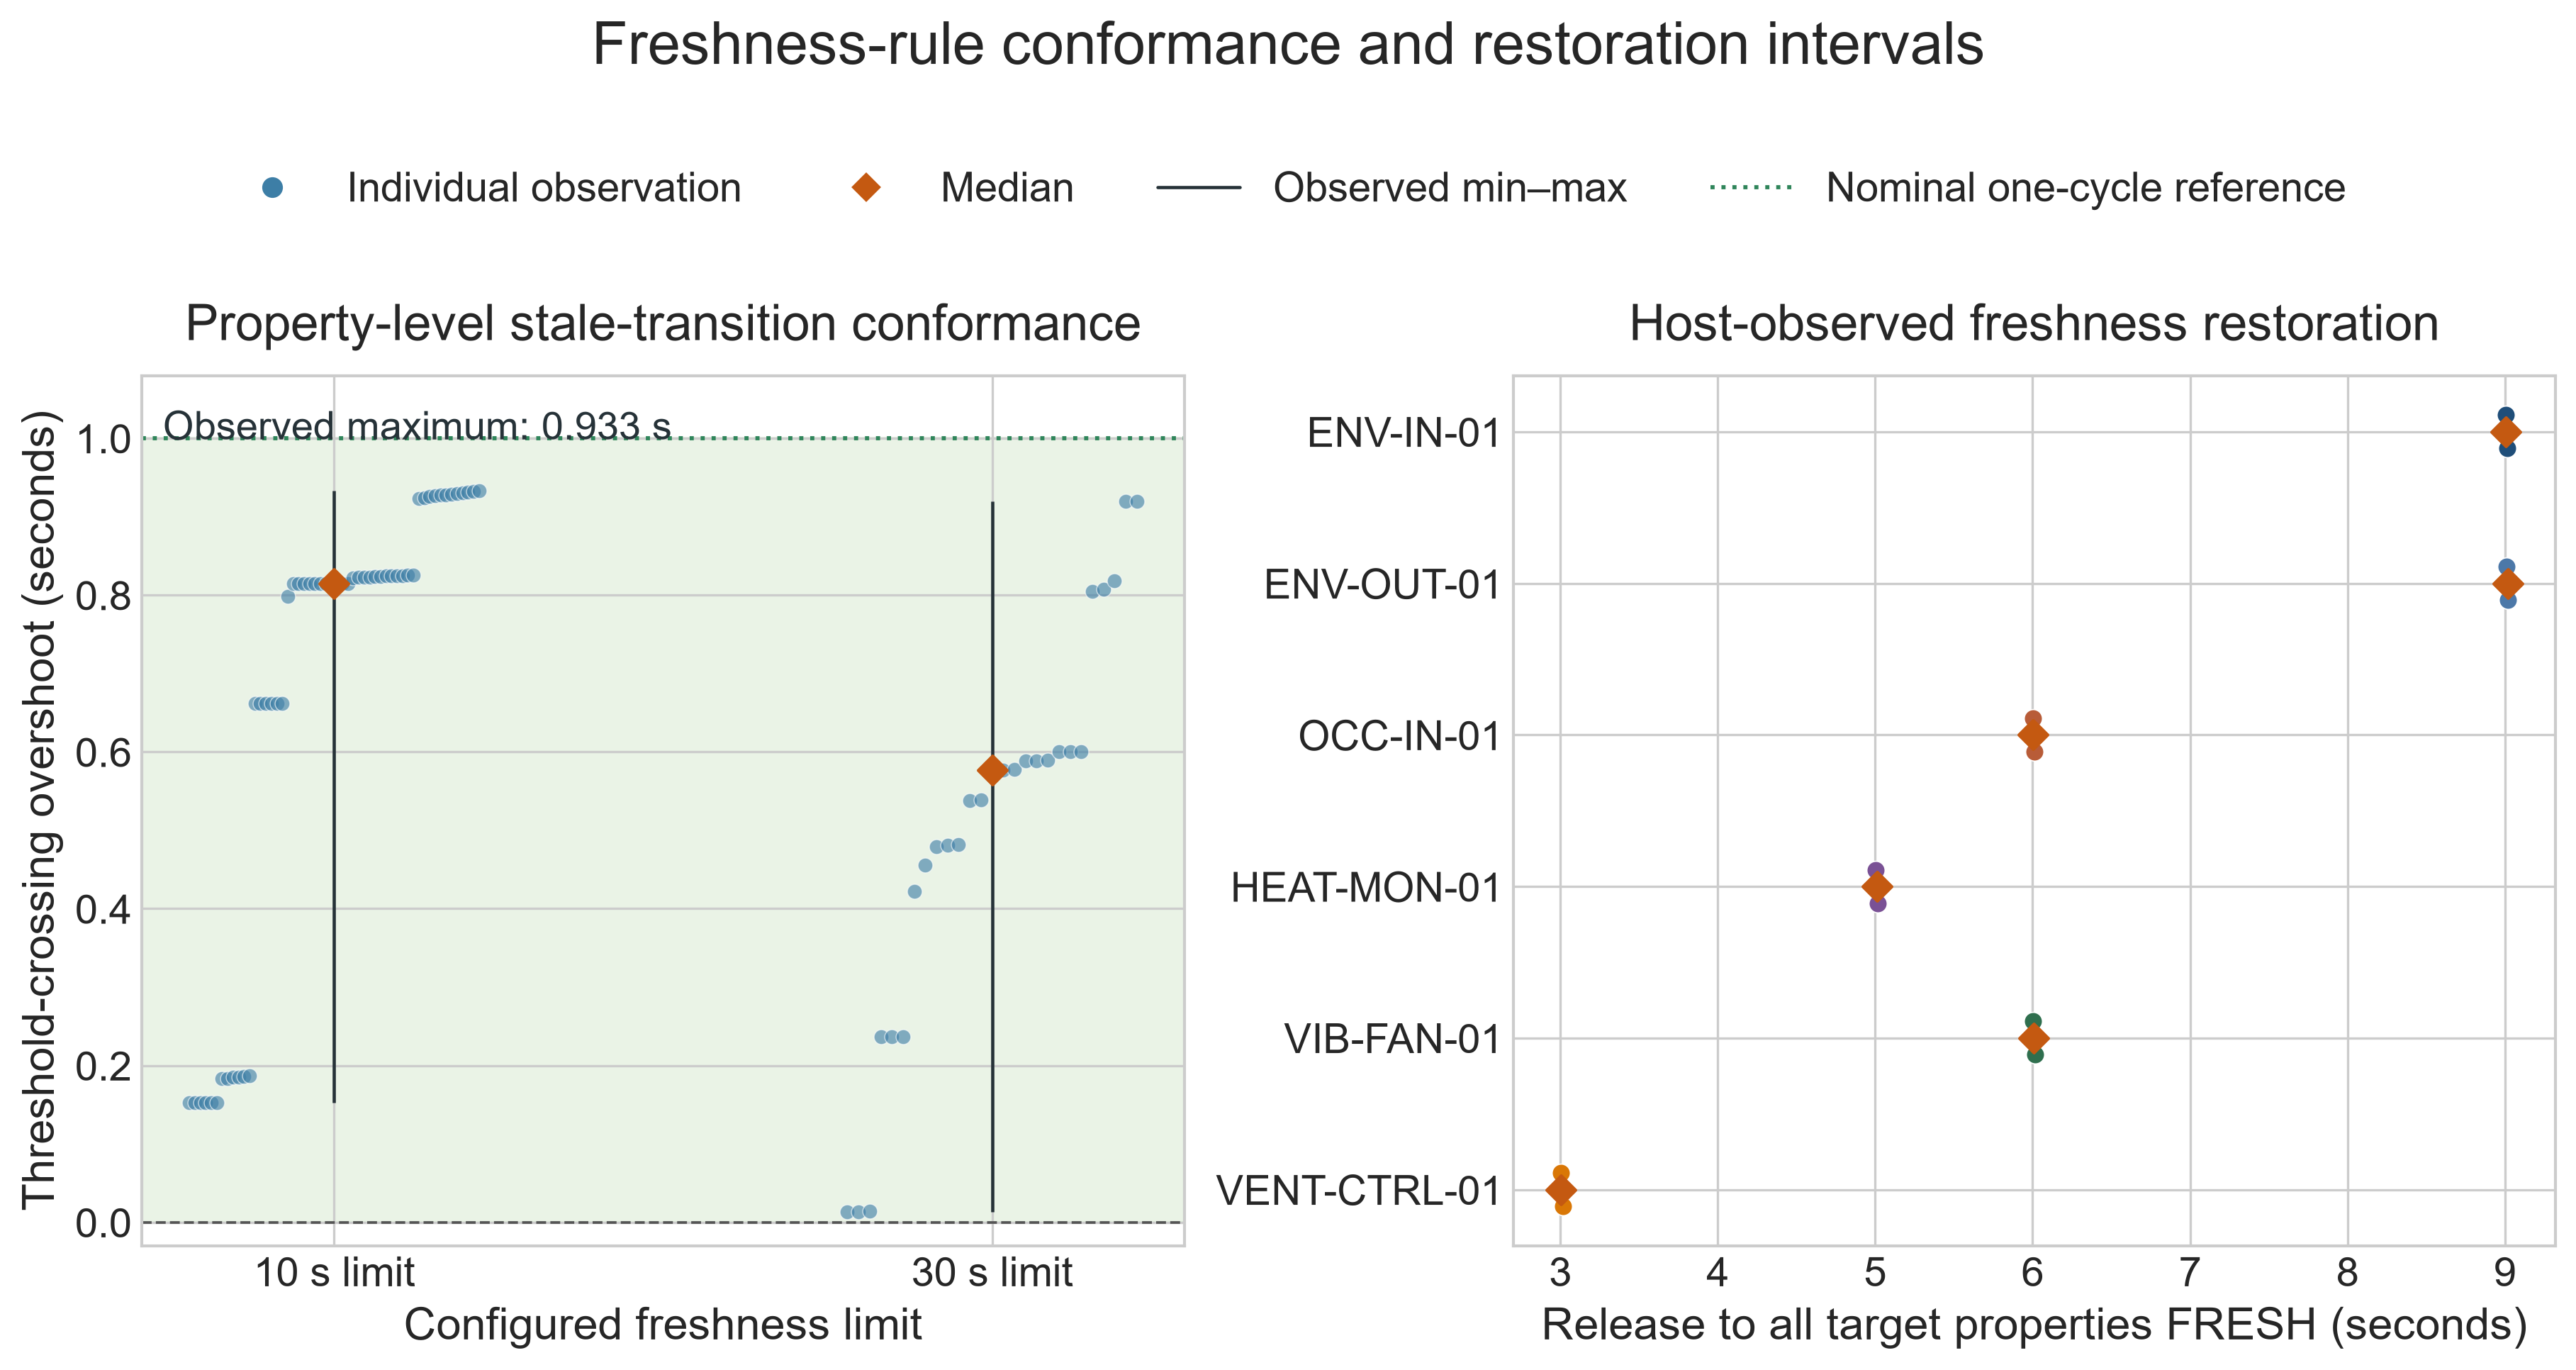

### Freshness loss and restoration

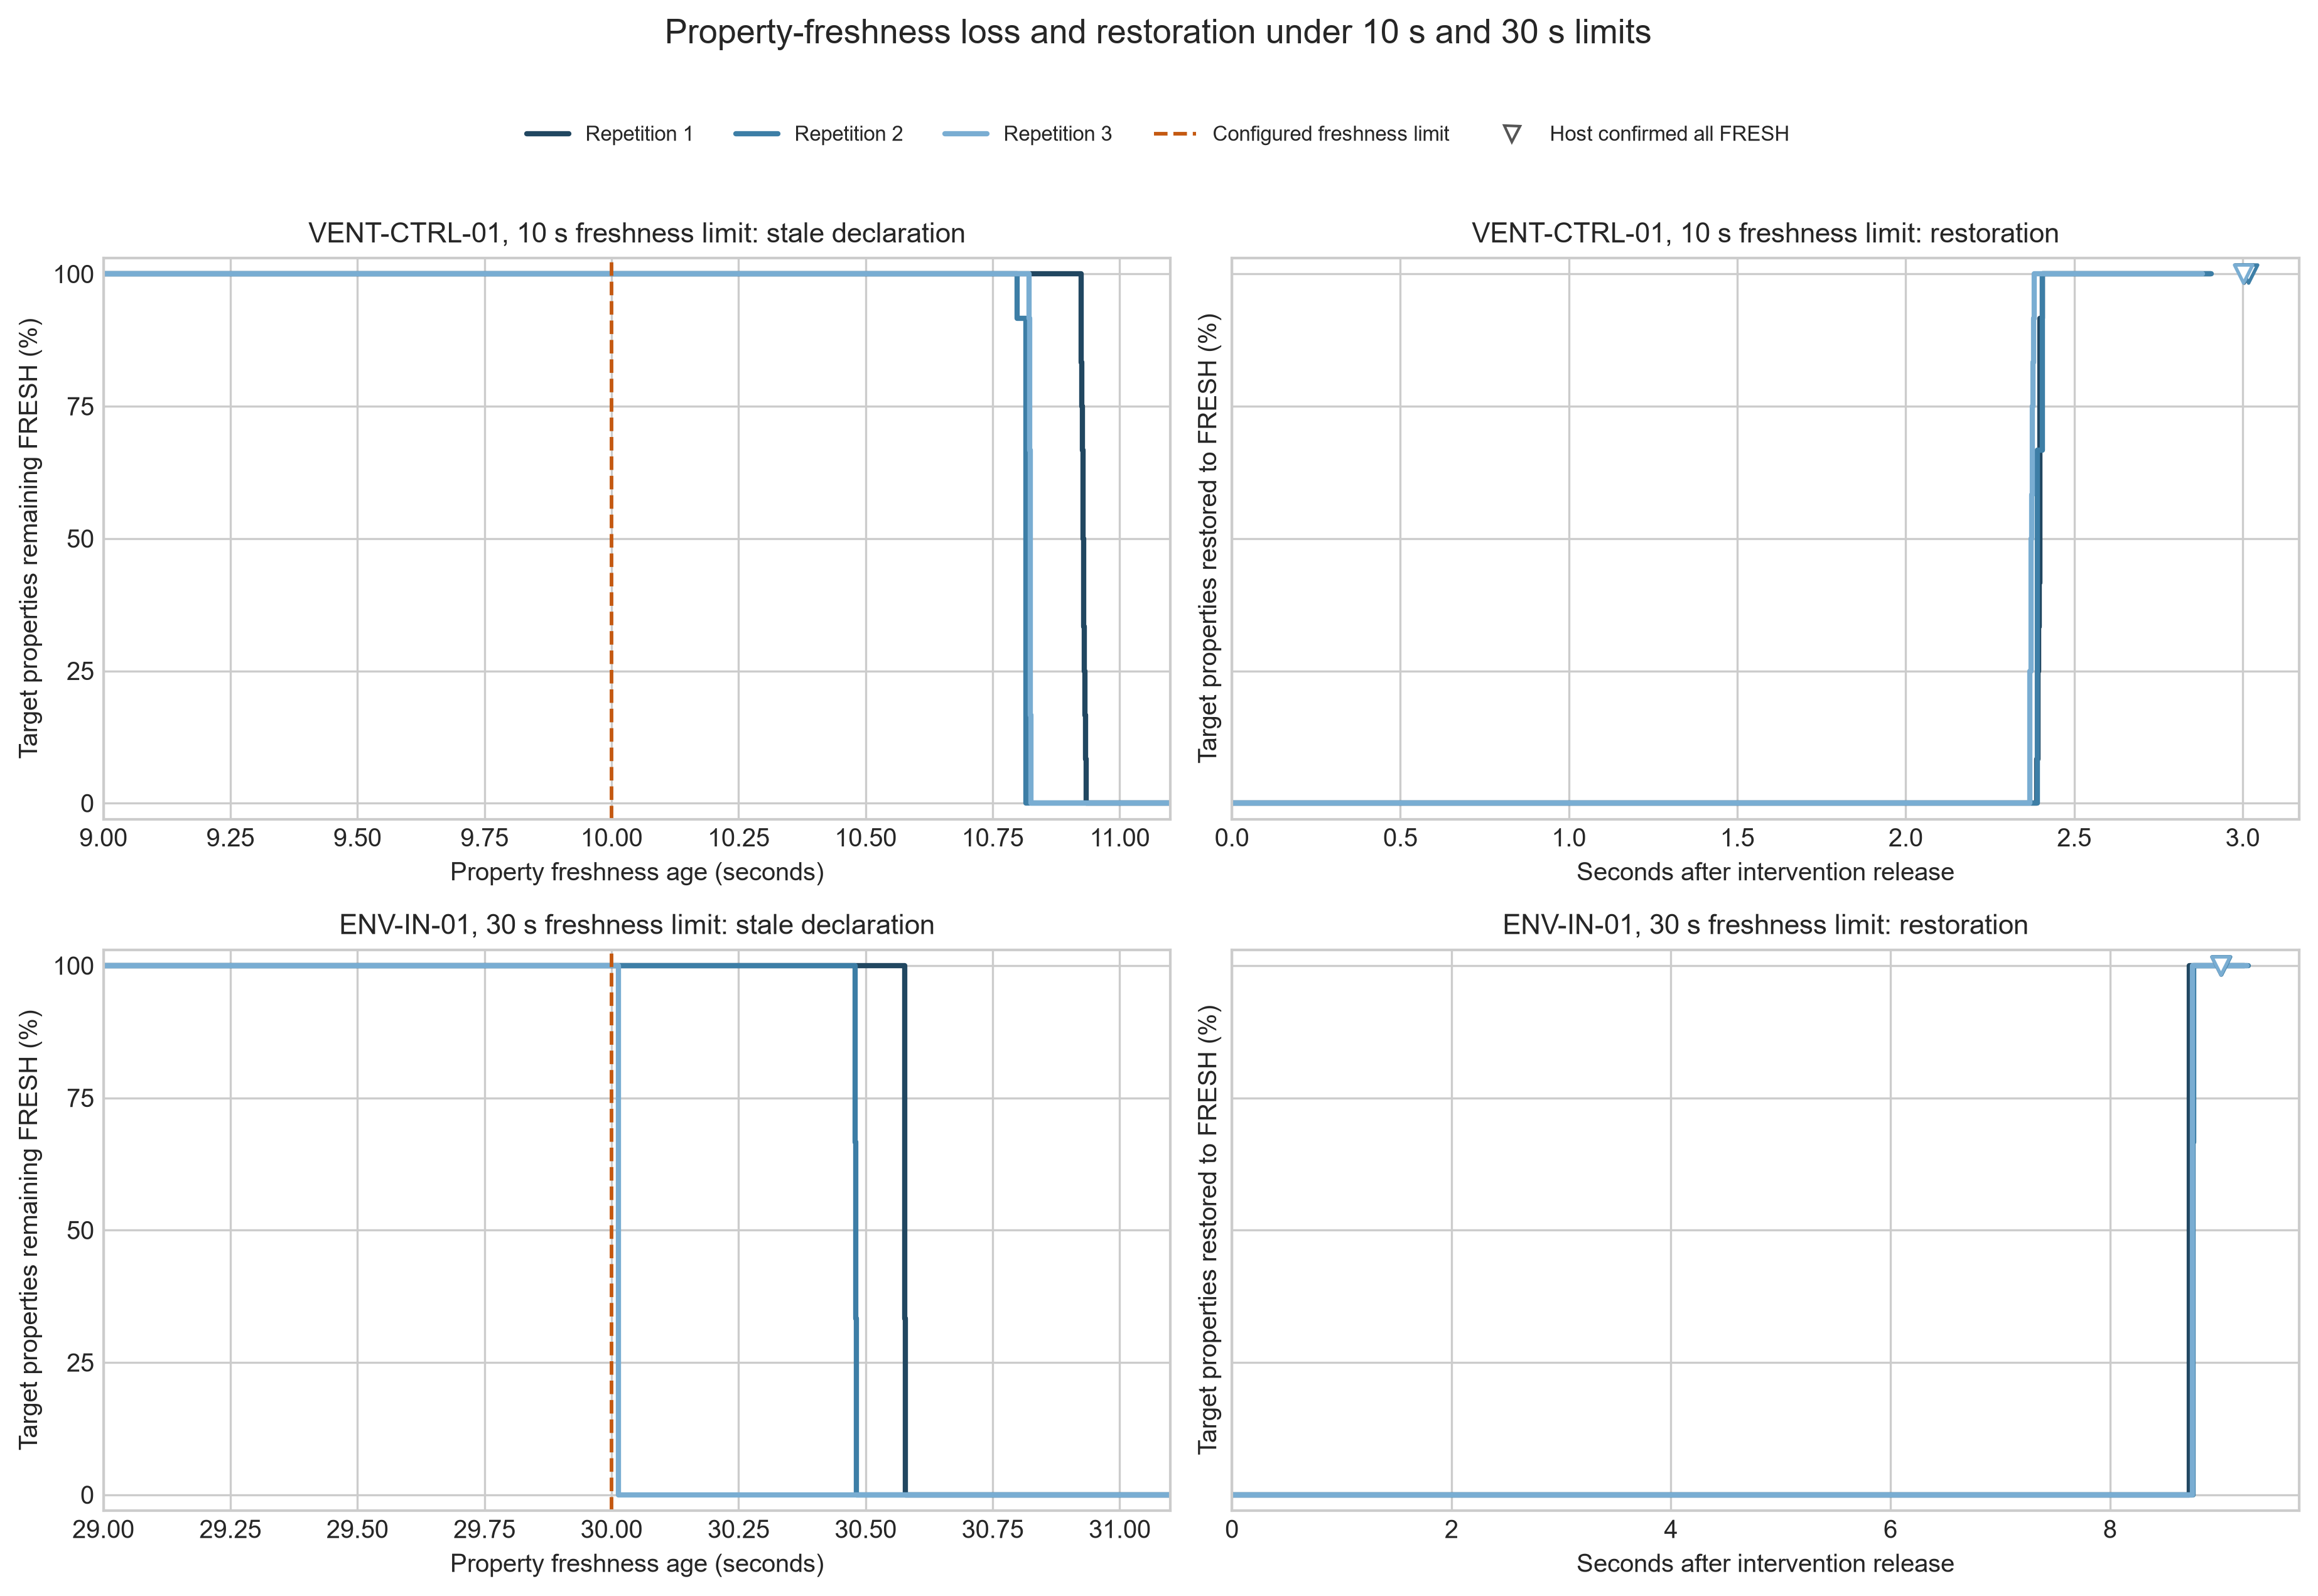

### Measurements during repeated telemetry interruptions

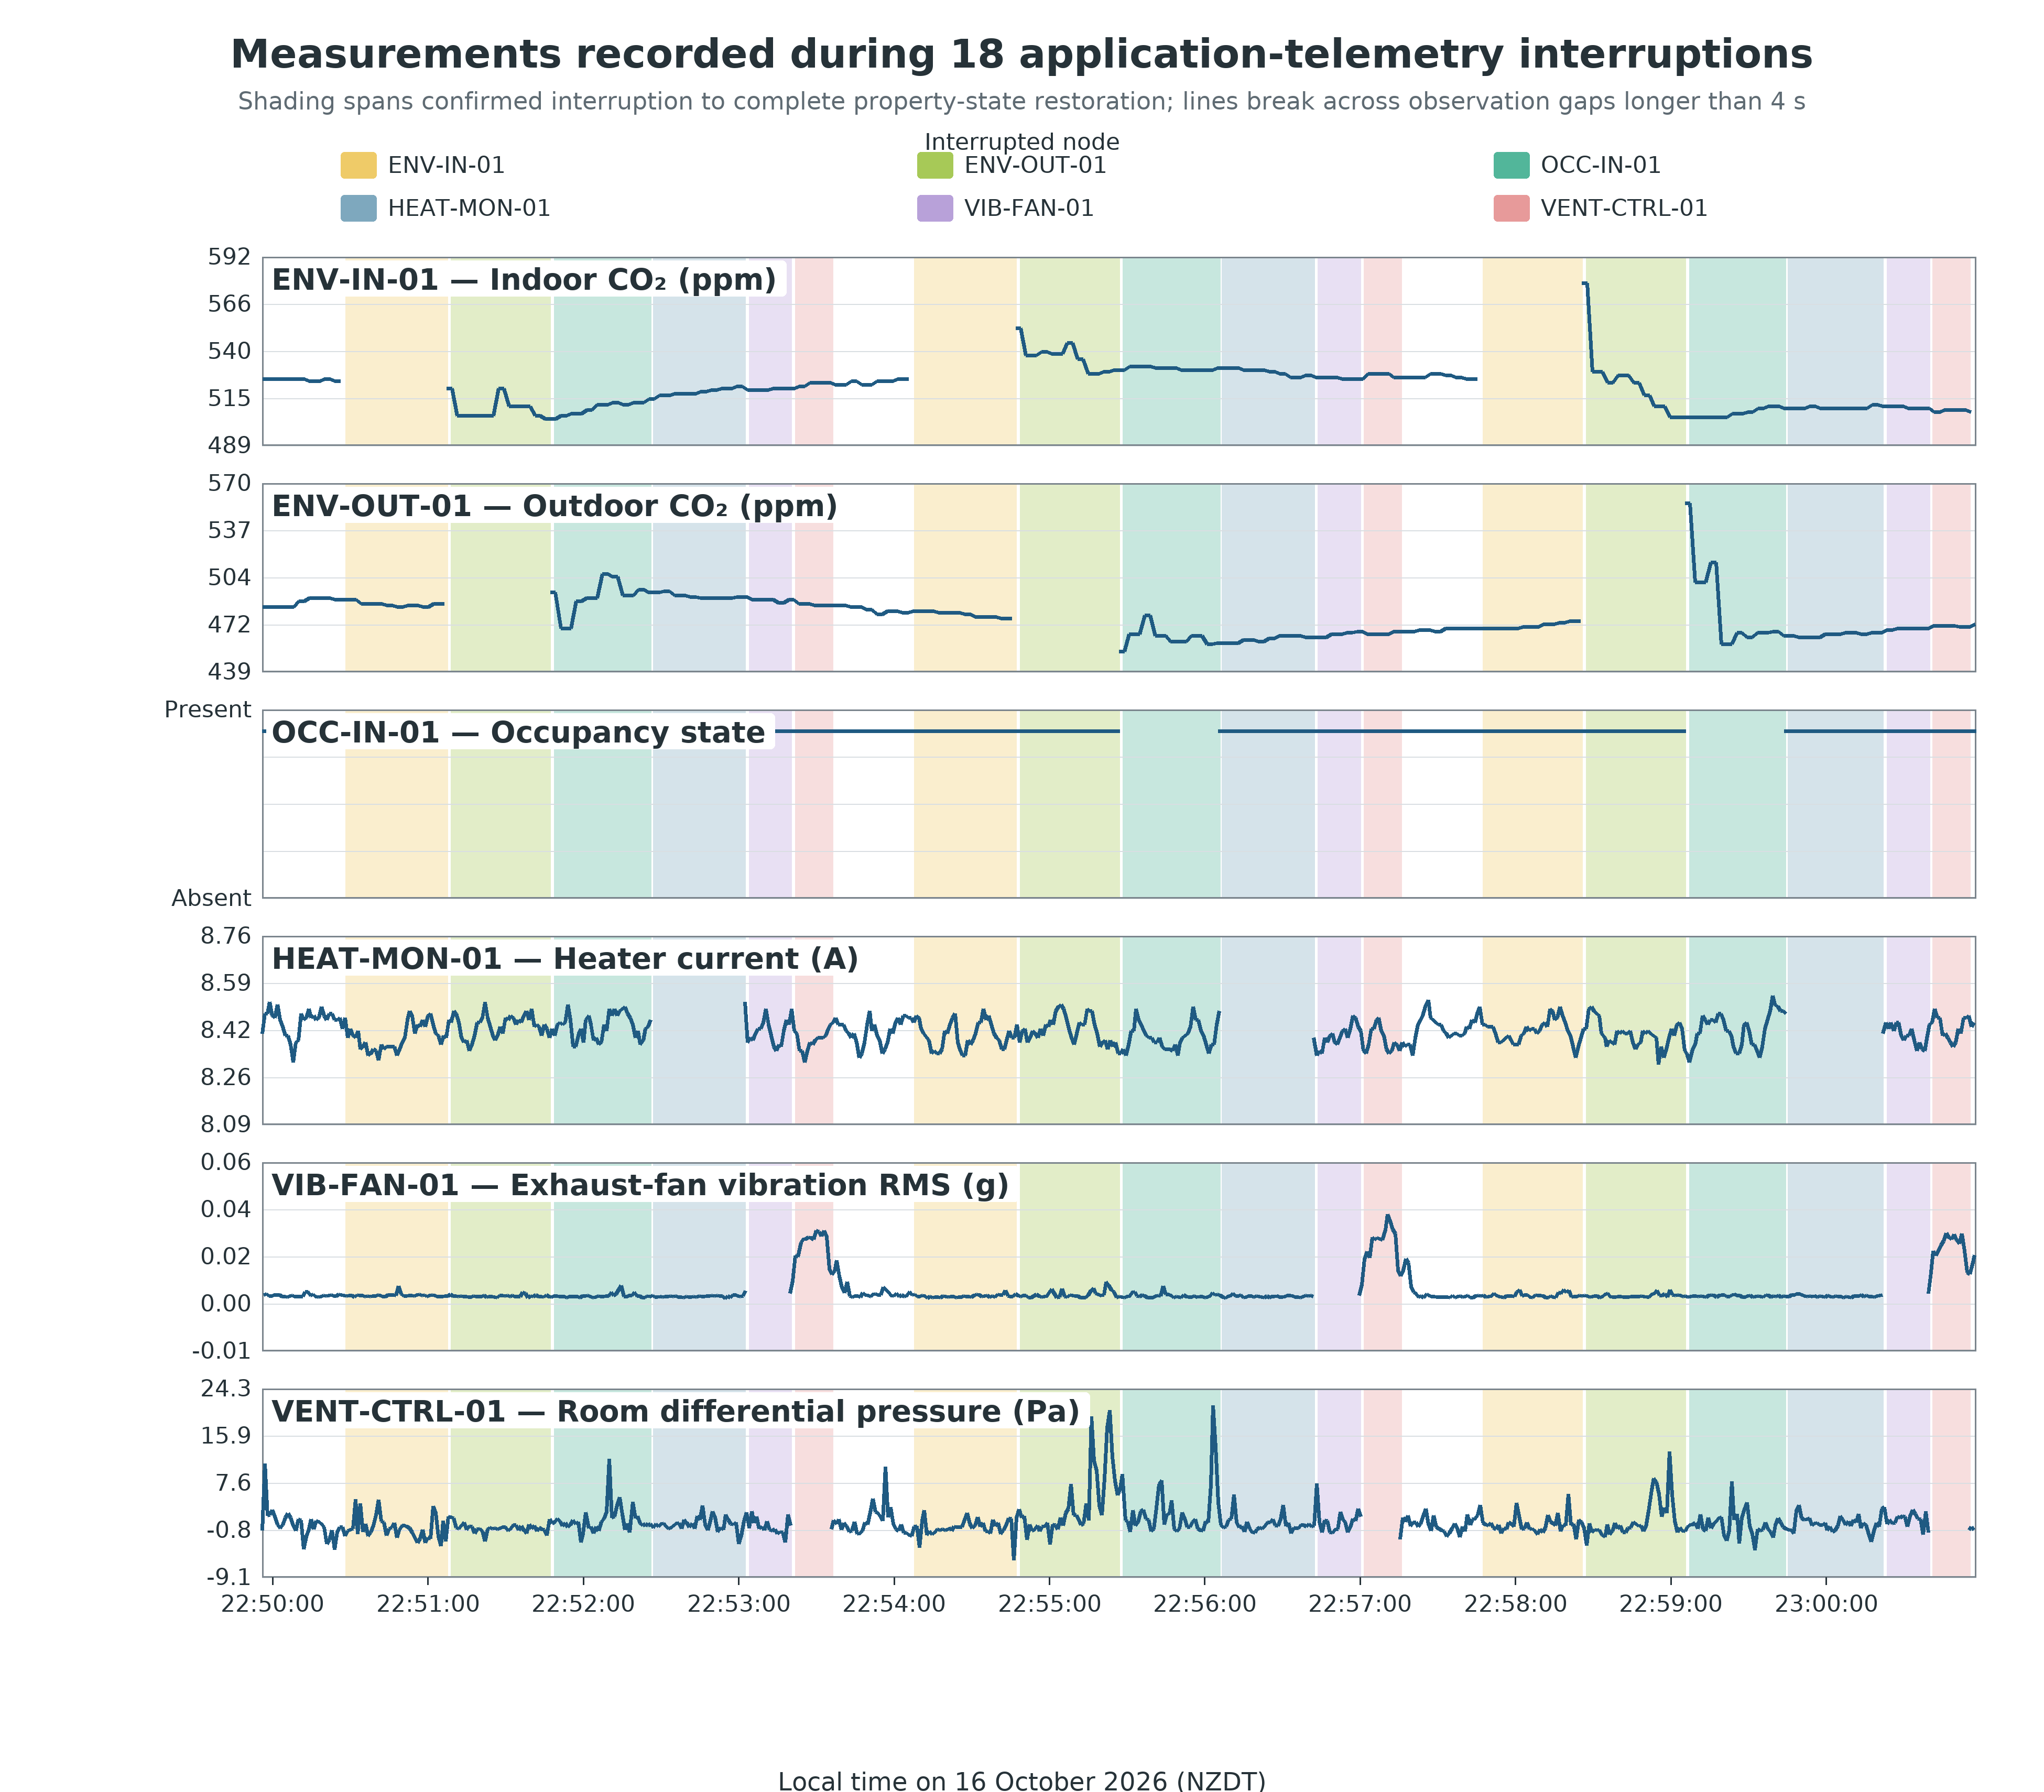

In [12]:
from indoortwin.evidence import display_plots
display_plots("02")
